In [2]:
# Import all libraries needed for the assignment
# - pandas/numpy for data handling
# - matplotlib for visualization (EDA + plots)
# - sklearn for training/testing models
# - mlflow for tracking experiments + logging models (deployment-ready artifacts)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix

In [3]:
#Quick check that MLflow can be imported correctly
import mlflow
import mlflow.sklearn
print("MLflow imported successfully")

MLflow imported successfully


In [4]:
df = pd.read_csv("Electrical Grid Stability.csv")
df.head()
# Loads the dataset from CSV and preview the first rows
# This confirms the dataset loaded correctly and shows the column names.

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [5]:
df.shape
df.info()
# Check dataset size and data types
# - df.shape shows number of rows and columns
# - df.info shows column data types and missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  object 
dtypes: float64(13), object(1)
memory usage: 1.1+ MB


Missing values per column:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64

Class distribution (stabf):
stabf
unstable    6380
stable      3620
Name: count, dtype: int64


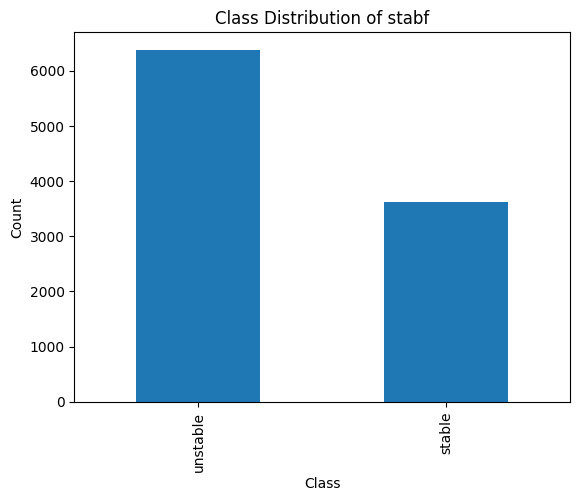

In [6]:
# (EDA)Explore data quality and target class distribution
# - Missing values check
# - Count of stable vs unstable in stabf
# - Bar plot for class balance
print("Missing values per column:")
print(df.isnull().sum())

print("\nClass distribution (stabf):")
print(df["stabf"].value_counts())

df["stabf"].value_counts().plot(kind="bar")
plt.title("Class Distribution of stabf")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [7]:
# Define inputs (features) and targets
# - X = all feature columns (drop stab and stabf)
# - y_reg = stab (numeric) -> regression task
# - y_clf = stabf (stable/unstable) -> classification task
X = df.drop(columns=["stab", "stabf"])
y_reg = df["stab"]     # regression target
y_clf = df["stabf"]    # classification target

In [8]:
#Split the dataset into training and testing sets
# - For regression (stab): normal train/test split
# - For classification (stabf): use stratify to keep class balance in train/test
# stab (regression)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# stabf (classification) - stratify like you did before
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

In [9]:
#Create / set an MLflow experiment
# This groups all runs (regression + classification + tuning) under one experiment name.
mlflow.set_experiment("Activity2_Grid_Stability")
print("MLflow experiment set")

2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.schemas
2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.tables
2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.types
2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.constraints
2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.defaults
2026/01/15 20:45:01 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.comments
2026/01/15 20:45:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/01/15 20:45:02 INFO mlflow.store.db.utils: Updating database tables
2026/01/15 20:45:02 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2026/01/15 20:45:02 INFO alembic.runtime.migration: Will assume non-transactional DDL.
2026/01/15 20:45:02 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2026/01/15 20:45:02 INFO alembic.runtime

MLflow experiment set


In [10]:
# Regression model for target 'stab' using Linear Regression
# - Train model
# - Predict on test set
# - Evaluate using MSE, RMSE, R2
# - Log params/metrics/model to MLflow (deployment-ready artifact)
with mlflow.start_run(run_name="stab_linear_regression"):

    # Train model
    reg_model = LinearRegression()
    reg_model.fit(X_train_r, y_train_r)

    # Predict
    y_pred_r = reg_model.predict(X_test_r)

    # Metrics
    mse = mean_squared_error(y_test_r, y_pred_r)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_r, y_pred_r)

    print("stab Regression Performance:")
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2:", r2)

    # Log to MLflow (same idea as guide: params + metrics + model)
    mlflow.log_param("model", "LinearRegression")
    mlflow.log_metric("mse", mse)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(reg_model, "stab_model")


2026/01/15 20:45:06 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/01/15 20:45:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instea

stab Regression Performance:
MSE: 0.0004822384863927187
RMSE: 0.021959929107187907
R2: 0.644463542856677


In [11]:
# Classification model for target 'stabf' using kNN
# IMPORTANT: kNN is distance-based, so we must scale features (StandardScaler).
# - Scale X_train and X_test
# - Train kNN baseline (k=5)
# - Predict and evaluate using accuracy/precision/recall/F1
# - Log params/metrics/model to MLflow
with mlflow.start_run(run_name="stabf_knn_baseline"):

    # Scaling 
    scaler = StandardScaler()
    X_train_c_scaled = scaler.fit_transform(X_train_c)
    X_test_c_scaled = scaler.transform(X_test_c)

    # Train kNN
    knn_model = KNeighborsClassifier(n_neighbors=5)
    knn_model.fit(X_train_c_scaled, y_train_c)

    # Predict
    y_pred_c = knn_model.predict(X_test_c_scaled)

    # Metrics
    acc = accuracy_score(y_test_c, y_pred_c)
    prec = precision_score(y_test_c, y_pred_c, pos_label="unstable")
    rec = recall_score(y_test_c, y_pred_c, pos_label="unstable")
    f1 = f1_score(y_test_c, y_pred_c, pos_label="unstable")

    print("stabf Classification Performance (k=5):")
    print("Accuracy:", acc)
    print("Precision:", prec)
    print("Recall:", rec)
    print("F1:", f1)

    # Log to MLflow 
    mlflow.log_param("model", "KNeighborsClassifier")
    mlflow.log_param("n_neighbors", 5)
    mlflow.log_metric("accuracy", acc)
    mlflow.log_metric("precision", prec)
    mlflow.log_metric("recall", rec)
    mlflow.log_metric("f1", f1)

    mlflow.sklearn.log_model(knn_model, "stabf_knn_baseline_model")


2026/01/15 20:45:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


stabf Classification Performance (k=5):
Accuracy: 0.8625
Precision: 0.8547129695251595
Recall: 0.945141065830721
F1: 0.8976553777446967


Best k: 10
Best Accuracy: 0.8795


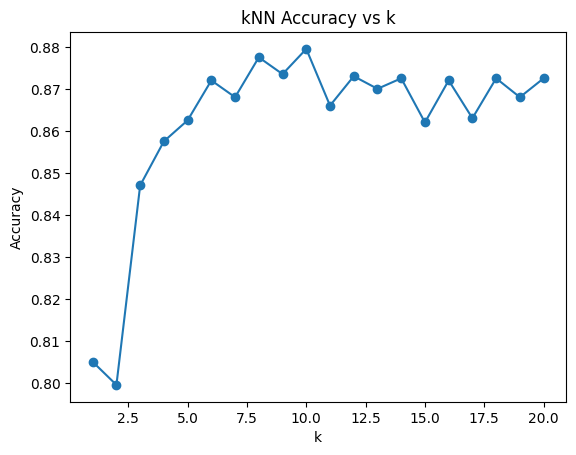

In [12]:
# Hyperparameter tuning for kNN (D)
# Try k from 1 to 20 and store accuracy values.
# Then pick best_k and visualize Accuracy vs k.
k_values = list(range(1, 21))
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_c_scaled, y_train_c)
    preds = model.predict(X_test_c_scaled)
    acc_k = accuracy_score(y_test_c, preds)
    accuracies.append(acc_k)

best_k = k_values[accuracies.index(max(accuracies))]
best_acc = max(accuracies)

print("Best k:", best_k)
print("Best Accuracy:", best_acc)

plt.plot(k_values, accuracies, marker="o")
plt.title("kNN Accuracy vs k")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.show()

In [14]:
# Train the final tuned kNN model using best_k (C)
# Evaluate it using classification metrics (E) and confusion matrix.
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_c_scaled, y_train_c)

y_pred_best = knn_best.predict(X_test_c_scaled)

acc_best = accuracy_score(y_test_c, y_pred_best)
prec_best = precision_score(y_test_c, y_pred_best, pos_label="unstable")
rec_best = recall_score(y_test_c, y_pred_best, pos_label="unstable")
f1_best = f1_score(y_test_c, y_pred_best, pos_label="unstable")

print("Final tuned kNN Performance (stabf):")
print("Accuracy:", acc_best)
print("Precision:", prec_best)
print("Recall:", rec_best)
print("F1:", f1_best)

cm = confusion_matrix(y_test_c, y_pred_best)
print("Confusion Matrix:\n", cm)

Final tuned kNN Performance (stabf):
Accuracy: 0.8795
Precision: 0.8802351212343865
Recall: 0.9388714733542319
F1: 0.9086082669700417
Confusion Matrix:
 [[ 561  163]
 [  78 1198]]


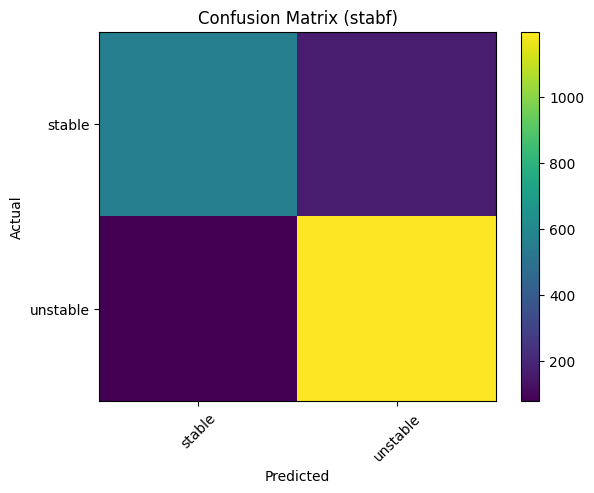

In [15]:
# Visualize confusion matrix
# This helps interpret model performance (where it confuses stable vs unstable).
plt.imshow(cm, aspect="auto")
plt.title("Confusion Matrix (stabf)")
plt.colorbar()
plt.xticks([0, 1], ["stable", "unstable"], rotation=45)
plt.yticks([0, 1], ["stable", "unstable"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [17]:
# (Deployment E): Log the tuned model to MLflow
# Logging the final model + metrics makes it stored as an artifact (ready for reuse/deployment).
with mlflow.start_run(run_name="stabf_knn_tuned"):

    mlflow.log_param("model", "KNeighborsClassifier")
    mlflow.log_param("best_k", best_k)

    mlflow.log_metric("accuracy", acc_best)
    mlflow.log_metric("precision", prec_best)
    mlflow.log_metric("recall", rec_best)
    mlflow.log_metric("f1", f1_best)

    mlflow.sklearn.log_model(knn_best, "stabf_knn_tuned_model")


print("Tuned model logged to MLflow")

2026/01/15 20:46:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Tuned model logged to MLflow
